In [144]:
import numpy as np
from rich import print
from contingency import Contingent
import matplotlib.pyplot as plt

from contingency.plots import PR_contour,ROC_contour


rng=np.random.default_rng(2)
np.set_printoptions(formatter={'float_kind':"{:.5g}".format})

# y_true = np.array([0,1,0,0,1,1,0,0]).astype(bool)
y_true = (rng.random(100)>0.6).astype(bool)
# y_prob = np.array([0.1,0.8,0.1,.7,.25,0.68,0.5,0.6])
y_pred = np.where(rng.random(100)<0.05, 1-y_true, y_true).astype(bool)

# y_pred = np.array([0,1,0,1,0,1,0,1]).astype(bool)
y_prob = 10*rng.beta(
    np.where(y_true, 3, 1.),
    np.where(y_true, 1., 3)
)

# M = Contingent(y_pred = y_pred, y_true=y_true)
M = Contingent.from_scalar(y_true, y_prob)

f1_thres,f1_opt = M.optimize('F', include_thres=True)
mcc_thres,mcc_opt = M.optimize('mcc', include_thres=True)

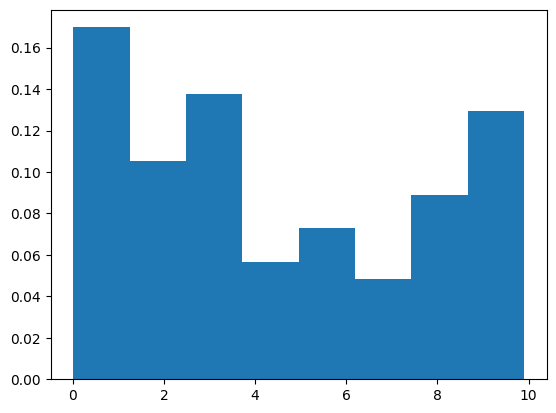

In [145]:
plt.hist(y_prob, bins='auto', density=True);

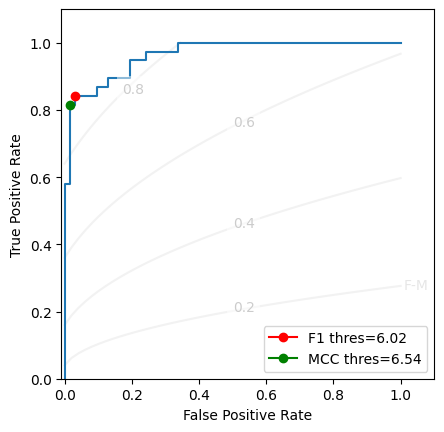

In [146]:
ROC_contour(M.imbalance, 'fm')
plt.plot(1-M.TNR, M.TPR)
plt.plot(f1_opt.FPR, f1_opt.TPR, marker='o', label=f'F1 thres={f1_thres:.2f}', c='r')
plt.plot(mcc_opt.FPR, mcc_opt.TPR, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')

plt.legend()
# plt.gca().spines[['top', 'right']].set_visible(False)

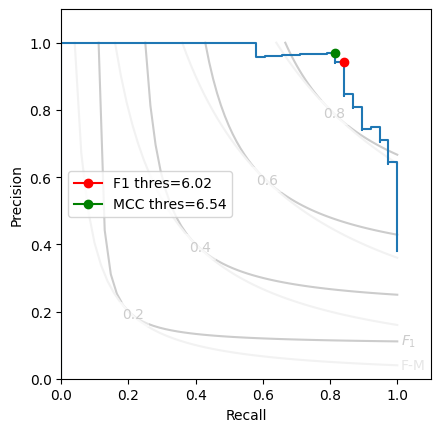

In [147]:
PR_contour()
plt.gca().set_aspect(1)
plt.step(M.recall, M.precision, where='post')


plt.plot(f1_opt.recall, f1_opt.precision, marker='o', label=f'F1 thres={f1_thres:.2f}', c='r')
plt.plot(mcc_opt.recall, mcc_opt.precision, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
# plt.annotate(
plt.legend()

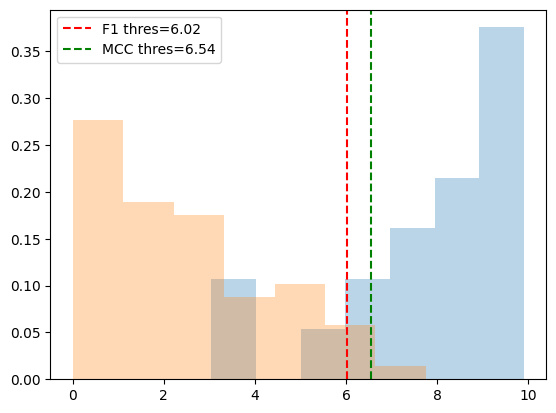

In [148]:
plt.hist(y_prob[y_true], bins='auto', density=True, alpha=0.3)
plt.hist(y_prob[~y_true], bins='auto', density=True, alpha=0.3)
# plt.axvline(0.5, color='0.4', ls='--')
plt.axvline(f1_thres, ls='--', c='r', label=f'F1 thres={f1_thres:.2f}')
plt.axvline(mcc_thres, ls='--', c='g', label=f'MCC thres={mcc_thres:.2f}')
plt.legend()


## 1. ROC Space: $TPR(FPR; m, \theta)$

To isolate $TPR$ as an explicit function of $FPR$, target $MCC = m$, and the imbalance ratio $\theta = \frac{N}{P}$, evaluate the standard quadratic equation:

$$TPR(FPR; m, \theta) = \frac{-B + \sqrt{B^2 - 4AC}}{2A}$$

### The Coefficients:
Evaluate these three coefficients sequentially using your independent variable $FPR$ along with constants $m$ and $\theta$:

*   **$A = m^2 + \theta$**
*   **$B = 2\theta \cdot FPR(m^2 - 1) - m^2(\theta + 1)$**
*   **$C = \theta \cdot FPR \left[ FPR(m^2\theta + 1) - m^2(\theta + 1) \right]$**

*Note: The positive root ($+ \sqrt{\dots}$) naturally isolates the valid performance space above the random-guess diagonal line ($m > 0$).*

---

## 2. Precision-Recall Space: $P(R; m, \theta)$

In Precision-Recall space, mapping the imbalance ratio directly into the metric structure yields a clean explicit equation for **Precision ($P$)** as a function of **Recall ($R$)**:

$$P(R; m, \theta) = \frac{2R + m^2\theta + m\sqrt{\theta \left( m^2\theta + 4R(1-R) \right)}}{2R(\theta + 1)}$$

### Vectorized / Python-Friendly Form:
Factoring out the leading baseline scalar transforms the equation into a highly clean form for programming loops or array operations:

$$P(R; m, \theta) = \frac{1}{\theta + 1} \left[ 1 + \frac{m^2\theta + m\sqrt{\theta^2 m^2 + 4\theta R(1-R)}}{2R} \right]$$

---

## 3. Quick Structural Sanity Checks

*   **The Random Baseline ($m = 0$):** If you plug $m = 0$ into the P-R isoline equation, the fractional component inside the brackets collapses to zero, leaving exactly $P(R) = \frac{1}{\theta + 1}$. This matches your horizontal baseline representing a purely random classifier.
*   **The Right-Hand Anchor Point ($R = 1$):** At perfect Recall, the variance term $4\theta R(1-R)$ under the radical drops out completely. The P-R isoline simplifies to a static point at the far right edge of your plot:
$$P(1) = \frac{1 + m^2\theta}{\theta + 1}$$
